# Assignment 5 — Timeseries **or** Text

**DATAX504** · Due end of Week 10

Choose **one** track. Delete or leave unused the other section. Less scaffolding is intentional: design choices are part of the work.

| Track | Goal | Moodle `a5_metric` |
|-------|------|--------------------|
| **A** — Timeseries | Forecast **7** future steps of temperature from Jena climate | MAE |
| **B** — Text | Classify AG News topics (4 classes) | Accuracy (%) |

## Tasks (whichever track)
1. Prepare inputs (windowing **or** tokenisation / vectorisation)
2. Train a sequence model appropriate to the track
3. Report the metric above
4. Short written answers: architecture + how inputs were prepared

## Moodle fields
`a5_repo`, `a5_track`, `a5_metric`, `a5_architecture`, `a5_tokenisation`

## AI disclosure (required)
Fill the table in the next cell before you submit.


## AI disclosure

| Field | Your answer |
|-------|-------------|
| Tool / model |ChatGPT + GPT-6.1 Sol |
| Used for | |
| Verified how | |
| Not used for | |


In [1]:
TRACK = "A"  # "A" or "B" — Moodle a5_track

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

print("Selected track:", TRACK)


Selected track: A


---
# Track A — Timeseries (Jena)

Forecast the next **7** steps of `T (degC)` from a past window of observations.

You decide: lookback length, normalisation, train/val/test split, LSTM vs Conv1D vs other, and how you compute MAE on the original °C scale.


13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step 
CSV file: C:\00Waikato26B\504\week10\Assignment5\data\jena_climate_2009_2016.csv
File exists: True
Removed duplicate timestamps: 327
Hourly observations: 70129
Feature shape: (70129, 1)
Missing hourly temperatures: 88
Hourly grid check: OK
Training mean (°C): 9.10956
Training standard deviation (°C): 8.644982
Train / validation / test shapes: (49090, 1) (10519, 1) (10520, 1)
Normalised training mean: [6.962658e-08]
Normalised training standard deviation: [1.]
Training shapes: (49012, 72, 1) (49012, 7)
Validation shapes: (10348, 72, 1) (10348, 7)
Test shapes: (10291, 72, 1) (10291, 7)
Window shape and missing-value checks: OK


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,583 (17.90 KB)

 Trainable params: 4,583 (17.90 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3229 - mae: 0.4228 - val_loss: 0.2124 - val_mae: 0.3738
Epoch 2/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.1088 - mae: 0.2438 - val_loss: 0.0875 - val_mae: 0.2224
Epoch 3/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0640 - mae: 0.1890 - val_loss: 0.0740 - val_mae: 0.2029
Epoch 4/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0583 - mae: 0.1790 - val_loss: 0.0691 - val_mae: 0.1950
Epoch 5/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0547 - mae: 0.1720 - val_loss: 0.0648 - val_mae: 0.1869
Epoch 6/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0518 - mae: 0.1661 - val_loss: 0.0615 - val_mae: 0.1804
Epoch 7/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0498 - mae: 0.1618 - val_loss: 0.0583 - val_mae: 0.1742
Epoch 8/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0483 - mae: 0.1586 - val_loss: 0.0554 - val_mae: 0.1687
Epoch 9/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - lo

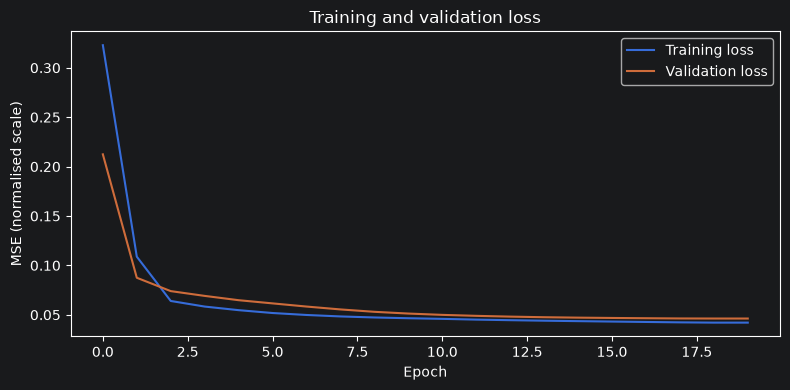

In [2]:
if TRACK == "A":

    from pathlib import Path
    from zipfile import ZipFile

    url = (
        "https://storage.googleapis.com/tensorflow/"
        "tf-keras-datasets/jena_climate_2009_2016.csv.zip"
    )

    zip_path = keras.utils.get_file(
        fname="jena_climate_2009_2016.csv.zip",
        origin=url,
        cache_dir=".",
        cache_subdir="data",
    )

    with ZipFile(zip_path, "r") as archive:
        csv_path = Path(
            archive.extract(
                "jena_climate_2009_2016.csv",
                path=Path(zip_path).parent,
            )
        )

    print("CSV file:", csv_path.resolve())
    print("File exists:", csv_path.is_file())

    import pandas as pd

    df = pd.read_csv(
        csv_path,
        usecols=["Date Time", "T (degC)"],
    )

    df["Date Time"] = pd.to_datetime(
        df["Date Time"],
        format="%d.%m.%Y %H:%M:%S",
        errors="raise",
    )

    # Sort timestamps and remove identical-temperature duplicates
    df = df.sort_values("Date Time", kind="stable")
    duplicate_count = int(df.duplicated(subset="Date Time").sum())
    df = df.drop_duplicates(subset="Date Time", keep="first")
    df = df.set_index("Date Time")

    # Compute hourly mean temperature; keep empty hours as NaN
    hourly_temperature = df["T (degC)"].resample(
        "1h",
        closed="left",
        label="left",
    ).mean()

    temperature = hourly_temperature.to_numpy(dtype=np.float32)
    features = temperature.reshape(-1, 1)

    # Verify a regular hourly grid, including missing hours
    intervals = hourly_temperature.index.to_series().diff().dropna()
    assert (intervals == pd.Timedelta(hours=1)).all()

    print("Removed duplicate timestamps:", duplicate_count)
    print("Hourly observations:", len(temperature))
    print("Feature shape:", features.shape)
    print("Missing hourly temperatures:", np.isnan(features).sum())
    print("Hourly grid check: OK")

    n = len(features)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    # Ignore missing values when calculating training statistics
    train_raw = features[:train_end]
    train_mean = np.nanmean(train_raw, axis=0)
    train_std = np.nanstd(train_raw, axis=0)

    if (
        not np.isfinite(train_mean).all()
        or not np.isfinite(train_std).all()
        or np.any(train_std <= 0)
    ):
        raise ValueError("Invalid training mean or standard deviation.")

    # Use training statistics for every split; missing values stay NaN
    features_normalised = (features - train_mean) / train_std

    train_data = features_normalised[:train_end]
    val_data = features_normalised[train_end:val_end]
    test_data = features_normalised[val_end:]

    print("Training mean (°C):", train_mean[0])
    print("Training standard deviation (°C):", train_std[0])
    print("Train / validation / test shapes:",
          train_data.shape, val_data.shape, test_data.shape)
    print("Normalised training mean:",
          np.nanmean(train_data, axis=0))
    print("Normalised training standard deviation:",
          np.nanstd(train_data, axis=0))

    lookback = 72
    horizon = 7

    def build_windows(data, lookback, horizon):
        X, y = [], []
        window_length = lookback + horizon

        for i in range(len(data) - window_length + 1):
            window = data[i:i + window_length]

            # Skip any window containing a missing or invalid value
            if not np.isfinite(window).all():
                continue

            X.append(window[:lookback])
            y.append(window[lookback:, 0])

        if not X:
            raise ValueError("No complete windows are available.")

        return (
            np.asarray(X, dtype=np.float32),
            np.asarray(y, dtype=np.float32),
        )

    # Build windows separately within each chronological split
    X_train, y_train = build_windows(train_data, lookback, horizon)
    X_val, y_val = build_windows(val_data, lookback, horizon)
    X_test, y_test = build_windows(test_data, lookback, horizon)

    print("Training shapes:", X_train.shape, y_train.shape)
    print("Validation shapes:", X_val.shape, y_val.shape)
    print("Test shapes:", X_test.shape, y_test.shape)

    for X, y in [
        (X_train, y_train),
        (X_val, y_val),
        (X_test, y_test),
    ]:
        assert X.shape[1:] == (lookback, 1)
        assert y.shape == (len(X), horizon)
        assert np.isfinite(X).all() and np.isfinite(y).all()

    print("Window shape and missing-value checks: OK")

    keras.utils.set_random_seed(504)

    model = keras.Sequential([
        layers.Input(shape=(lookback, X_train.shape[2])),
        layers.LSTM(32),
        layers.Dense(horizon),
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"],
    )

    model.summary()

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=64,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=1,
    )

    # Evaluate only on complete windows from the held-out test set
    predictions_normalised = model.predict(
        X_test,
        batch_size=64,
        verbose=0,
    )

    # Restore both predictions and targets to degrees Celsius
    predictions_celsius = (
        predictions_normalised * train_std[0] + train_mean[0]
    )
    targets_celsius = y_test * train_std[0] + train_mean[0]

    assert predictions_celsius.shape == targets_celsius.shape
    assert np.isfinite(predictions_celsius).all()

    # Average across all test samples and all 7 forecast steps
    metric = float(
        np.mean(np.abs(predictions_celsius - targets_celsius))
    )

    print(f"Track A MAE (Moodle a5_metric): {metric:.4f} °C")

    plt.figure(figsize=(8, 4))
    plt.plot(history.history["loss"], label="Training loss")
    plt.plot(history.history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE (normalised scale)")
    plt.title("Training and validation loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print("Skipping Track A")


---
# Track B — Text (AG News)

Four-class news topic classification.

You decide: how to load AG News (TFDS or another source), vocabulary / sequence length, Embedding + LSTM / Transformer / other, and the train/val/test protocol.


In [ ]:
if TRACK == "B":
    # TODO: load AG News (or a documented subset)
    # TODO: text → integer sequences (TextVectorization, tokenizer, etc.)
    # TODO: define, compile, and fit a classifier for 4 classes
    # TODO: report test accuracy as a percentage for Moodle a5_metric
    #
    # metric = ...  # accuracy %
    metric = None
    print(f"Track B accuracy % (Moodle a5_metric): {metric}")
else:
    print("Skipping Track B")


---
## Written responses

### Architecture summary (Moodle `a5_architecture`, max 100 words)

*Layers, sizes, and why this design fits your track.*

### Input preparation (Moodle `a5_tokenisation`, max 100 words)

*Windowing / normalisation **or** tokenisation / padding / masking — whichever applies.*


*Your answers here.*
